# This creates the spatial context maps for ICB responders and non-responders as well as patients who did or did not progress following initial local disease

Import packages and neighborhood labeled data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%pylab inline
import seaborn as sns
import networkx as nx
import math
from itertools import product
import scipy as sp

Populating the interactive namespace from numpy and matplotlib


In [3]:
from sklearn.neighbors import NearestNeighbors
import time
import os
from itertools import product
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from sklearn.cluster import MiniBatchKMeans
import scanpy as sc

def get_windows(job,n_neighbors):
    start_time,idx,tissue_name,indices = job
    job_start = time.time()
    
    print ("Starting:", str(idx+1)+'/'+str(len(exps)),': ' + exps[idx])

    tissue = tissue_group.get_group(tissue_name)
    to_fit = tissue.loc[indices][[X,Y]].values

    fit = NearestNeighbors(n_neighbors=n_neighbors).fit(tissue[[X,Y]].values)
    m = fit.kneighbors(to_fit)

    #sort_neighbors
    args = m[0].argsort(axis = 1)
    add = np.arange(m[1].shape[0])*m[1].shape[1]
    sorted_indices = m[1].flatten()[args+add[:,None]]

    neighbors = tissue.index.values[sorted_indices]
   
    end_time = time.time()
   
    print ("Finishing:", str(idx+1)+"/"+str(len(exps)),": "+ exps[idx],end_time-job_start,end_time-start_time)
    return neighbors.astype(np.int32)

In [19]:
path_to_data = 'Z:/Max/MCC_project/CODEX_final_Data/CODEX_Annotations/Submission/MCC_single_cell_neighborhoods_markers.csv'
df_02 = pd.read_csv(path_to_data)

In [5]:
clin_metadata = pd.read_csv("Z:/Max/MCC_project/CODEX_final_Data/clinical_metadata/Clin_meta_dict_MCC_280224_unique_region_num.csv", index_col=0)
clin_metadata

,Unnamed: 0.1,Pat_ID,Gender,Age_diagnosis,Localization_biopsy,Localization_primary,tumor_thickness_mm,T,N,M,...,MCPyV_CODEX,MCPyV_positive_FU,p53_CODEX,pRB_CODEX,MHC-I_CODEX,MHC-I_IHC,HandE_phenotype,TMA_num,unique_region_num,unique_core_num
0,0,1,m,70,5,CUP,NaN,0.0,2,0,...,intermediate,NaN,low,low,high,high,excluded,TMA_1,TMA_1_reg044,TMA_1_J4
1,1,1,m,70,5,CUP,NaN,0.0,2,0,...,intermediate,NaN,low,low,high,high,excluded,TMA_2,TMA_2_reg044,TMA_2_J4
2,2,1,m,70,5,CUP,NaN,0.0,2,0,...,intermediate,NaN,low,low,high,high,excluded,TMA_3,TMA_3_reg044,TMA_3_J4
3,3,1,m,70,5,CUP,NaN,0.0,2,0,...,intermediate,NaN,low,low,high,high,excluded,TMA_41,TMA_41_reg044,TMA_41_J4
4,4,1,m,70,5,CUP,NaN,0.0,2,0,...,intermediate,NaN,low,low,high,high,excluded,TMA_22,TMA_22_reg044,TMA_22_J4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
490,490,81,m,86,1,Head,9.3,2.0,2,0,...,negative,NaN,low,intermediate,NaN,intermediate,anergic,TMA_5,TMA_5_reg018,TMA_5_5B
491,491,82,f,81,1,Head,11.0,2.0,0,0,...,negative,NaN,high,low,NaN,intermediate,anergic,TMA_5,TMA_5_reg005,TMA_5_2A
492,492,82,f,81,1,Head,11.0,2.0,0,0,...,negative,NaN,high,low,NaN,intermediate,anergic,TMA_5,TMA_5_reg009,TMA_5_3A
493,493,82,f,81,1,Head,11.0,2.0,0,0,...,negative,NaN,high,low,NaN,intermediate,anergic,TMA_5,TMA_5_reg013,TMA_5_4A


In [20]:
filter_columns = ["CA-IX", 'CD31', 'CD38', 'CD8', 'FoxP3', 'CD103', 'CHGA', 'CXCL9',
       'CD206', 'PD-1', 'pRB', 'MHC-I', 'CD45RO', 'PD-L1', 'CD56', 'CD45',
       'MMP9', 'CD21', 'CD163', 'CXCL13', 'CXCL10', 'GATA3', 'EZH2', 'CD11b',
       'B7-H3', 'CD57', 'CXCR5', 'Synaptophysin', 'LAG3', 'CD3', 'IRF4',
       'Vimentin', 'CD25', 'CLEC9A', 'IL-10', 'TCF1/7', 'CD73', 'CD68',
       'EOMES', 'CD11c', 'CD4', 'aSMA', 'IRF8', 'GranzymeB', 'CD20', 'MCPyV',
       'CK20', 'Podoplanin', 'CollagenIV', 'CD15', 'Tbet', 'p53', 'CXCR3',
       'HLA-DR', 'CCL5', 'CD45RA', 'FAP', 'Ki67', 'x', 'y', 'UID', 'unique_core_num', 'TMA_core_num', 'cell_types_lowres', 'cell_types_mediumres', 'cell_types_highres', 'tissue_compartments', "CN_k20_n25_annot",
                    'PDL1_cluster_pos', "PD1_cluster_pos", 'CXCL9_pos', "CPI_ORR", "CPI_Progress_status",
                    "Baseline_FU_biopsy", "Progress_to_metastatic_disease","Local_disease"]

df_02 = df_02[filter_columns]
df_02

,CA-IX,CD31,CD38,CD8,FoxP3,CD103,CHGA,CXCL9,CD206,PD-1,...,tissue_compartments,CN_k20_n25_annot,PDL1_cluster_pos,PD1_cluster_pos,CXCL9_pos,CPI_ORR,CPI_Progress_status,Baseline_FU_biopsy,Progress_to_metastatic_disease,Local_disease
0,-0.189319,-0.258097,-0.072743,-0.150902,0.107365,-0.279769,0.099805,-0.139105,-0.924909,-0.412854,...,tumor,Tumor boundary,0,0,0,1.0,0.0,pre,1,0
1,-0.080008,-0.135732,0.400490,-0.080105,-0.484726,-1.087888,-0.869184,-0.139617,-0.181999,0.167542,...,tumor,Bulk tumor,0,0,0,1.0,0.0,pre,1,0
2,-0.119020,-0.065536,-0.052366,-0.082031,-0.194730,-0.198401,0.189011,-0.131043,0.234852,0.007967,...,tumor,Bulk tumor,0,0,0,1.0,0.0,pre,1,0
3,-0.046333,-0.165931,-0.080775,-0.114701,0.118215,-0.025465,-0.876562,0.002013,0.352675,0.222285,...,tumor,Tumor boundary,0,0,0,1.0,0.0,pre,1,0
4,0.216484,-0.042094,0.723048,0.020116,0.167595,-0.546050,1.763190,0.140371,0.903630,0.397745,...,tumor,Myeloid-cell enriched immune infiltrate,0,0,0,1.0,0.0,pre,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7981312,1.872633,0.121872,0.124288,-0.269062,-0.150562,-0.296521,-0.715245,-0.221346,-0.411416,-0.318869,...,tumor,Bulk tumor,0,0,0,NaN,NaN,pre,0,0
7981313,1.767126,0.328083,0.438761,-0.265800,-0.030187,-0.029010,0.718355,-0.207678,0.575560,0.109031,...,tumor,Tumor boundary,0,0,0,NaN,NaN,pre,0,0
7981314,1.629973,1.157424,-0.366828,-0.281206,-0.078289,-0.311348,1.761115,-0.218399,-0.083377,-0.326309,...,stroma,Tumor boundary,0,0,0,NaN,NaN,pre,0,0
7981315,0.151221,2.001018,-0.323009,-0.268104,0.440981,0.401452,2.566878,2.687779,0.063502,-0.037167,...,stroma,Vessel-enriched stroma,0,0,0,NaN,NaN,pre,0,0


Import modules from cellhier for neighborhoods

In [21]:
import sys
sys.path.append('Z:/Max/Computation/python_code/')
from cellhier.knn_graph_neighborhood import Neighborhoods

Create cell neighborhoods with a window size of 100 nearest neighbors with regard to the neighborhood

In [22]:
df = df_02.copy()

In [23]:
df.CN_k20_n25_annot

0                                   Tumor boundary
1                                       Bulk tumor
2                                       Bulk tumor
3                                   Tumor boundary
4          Myeloid-cell enriched immune infiltrate
                            ...                   
7981312                                 Bulk tumor
7981313                             Tumor boundary
7981314                             Tumor boundary
7981315                     Vessel-enriched stroma
7981316                             Tumor boundary
Name: CN_k20_n25_annot, Length: 7981317, dtype: object

In [25]:
n_num = 100
ks=[n_num]
cluster_col = 'CN_k20_n25_annot'
sum_cols=df[cluster_col].unique()
keep_cols = ['UID', "unique_core_num", "cell_types_mediumres", "cell_types_highres",
       'CN_k20_n25_annot', 'CPI_ORR', 'CPI_Progress_status', "Progress_to_metastatic_disease", "Local_disease",
       'Baseline_FU_biopsy','x', 'y', "PDL1_cluster_pos", "PD1_cluster_pos"]
X='x'
Y='y'
Reg = 'unique_core_num'
Neigh = Neighborhoods(df,ks,cluster_col,sum_cols,keep_cols,X,Y,reg=Reg,add_dummies=True)
windows = Neigh.k_windows()
save_path = 'Z:/Max/MCC_project/CODEX_final_Data/Output/Spatial_contexts/'

Starting: 70/356 : TMA_1_A1
Finishing: 70/356 : TMA_1_A1 2.160069465637207 2.220893383026123
Starting: 58/356 : TMA_1_A2
Finishing: 58/356 : TMA_1_A2 0.7144792079925537 2.980201244354248
Starting: 44/356 : TMA_1_A3
Finishing: 44/356 : TMA_1_A3 0.23300433158874512 3.2402329444885254
Starting: 32/356 : TMA_1_A4
Finishing: 32/356 : TMA_1_A4 1.0183336734771729 4.258566617965698
Starting: 20/356 : TMA_1_A5
Finishing: 20/356 : TMA_1_A5 0.799454927444458 5.09014368057251
Starting: 76/356 : TMA_1_B1
Finishing: 76/356 : TMA_1_B1 0.7899987697601318 5.9094626903533936
Starting: 63/356 : TMA_1_B2
Finishing: 63/356 : TMA_1_B2 0.35295915603637695 6.293596029281616
Starting: 50/356 : TMA_1_B3
Finishing: 50/356 : TMA_1_B3 0.529984712600708 6.833725452423096
Starting: 37/356 : TMA_1_B4
Finishing: 37/356 : TMA_1_B4 0.3814401626586914 7.247044801712036
Starting: 25/356 : TMA_1_B5
Finishing: 25/356 : TMA_1_B5 0.36831021308898926 7.614355564117432
Starting: 13/356 : TMA_1_B6
Finishing: 13/356 : TMA_1_B6 0.

-------------------------

In [26]:
#Choose the windows size to continue with
w = windows[n_num]

In [28]:
list(w.CN_k20_n25_annot.unique())

['Tumor boundary',
 'Bulk tumor',
 'Myeloid-cell enriched immune infiltrate',
 'Vessel-enriched stroma',
 'T cell priming and activation',
 'CAF-enriched stroma',
 'Follicle',
 'Plasma-cell enriched immune infiltrate',
 'B cell priming zone',
 'Granulocyte-enriched',
 'Epithelium']

In [29]:
pal_color = {
'Tumor boundary': '#5d5c61',
 'Myeloid-cell enriched immune infiltrate': 'sienna',
 'CAF-enriched stroma': 'orange',
 'B cell priming zone': '#3198b5',
 'T cell priming and activation': '#44CB63',
 'Bulk tumor': '#204F89',
 'Vessel-enriched stroma': 'red',
 'Plasma-cell enriched immune infiltrate': 'purple',
 'Epithelium': 'Magenta',
 'Follicle': '#0762eb',
 'Granulocyte-enriched': 'cyan'
}
l=list(pal_color.keys())

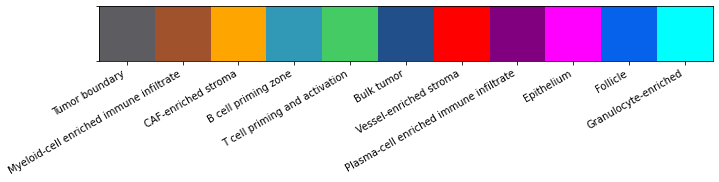

In [30]:
sns.palplot(pal_color.values())
plt.xticks(range(len(pal_color)),pal_color.keys(),rotation = 30,ha='right'
          );
plt.savefig(save_path+'color_map.png', dpi=600)

In [31]:
lmap = {j:i for i,j in enumerate(l)}
palt=pal_color
palt

{'Tumor boundary': '#5d5c61',
 'Myeloid-cell enriched immune infiltrate': 'sienna',
 'CAF-enriched stroma': 'orange',
 'B cell priming zone': '#3198b5',
 'T cell priming and activation': '#44CB63',
 'Bulk tumor': '#204F89',
 'Vessel-enriched stroma': 'red',
 'Plasma-cell enriched immune infiltrate': 'purple',
 'Epithelium': 'Magenta',
 'Follicle': '#0762eb',
 'Granulocyte-enriched': 'cyan'}

In [35]:
'''
this is the code that finds the minimal combination of CNs
required to make up a threshold percentage of assignments in a window
combinations are stored as a sorted tuple
'''
def get_thresh_simps(x,thresh):
    sorts = np.argsort(-x, axis = 1)
    x_sorted = -np.sort(-x, axis = 1)
    cumsums = np.cumsum(x_sorted,axis = 1)
    thresh_simps = pd.Series([tuple(sorted(sorts[i,:(1+j)])) for i,j in enumerate(np.argmax(cumsums>thresh,axis = 1))])
    return thresh_simps

## Compute the minimal combination of CNs required to make up a threshold percentage of assignemnets in a window

In [36]:
'''
this is the code that finds the minimal combination of CNs
required to make up a threshold percentage of assignments in a window
combinations are stored as a sorted tuple
'''
def get_thresh_simps(x,thresh):
    sorts = np.argsort(-x, axis = 1)
    x_sorted = -np.sort(-x, axis = 1)
    cumsums = np.cumsum(x_sorted,axis = 1)
    thresh_simps = pd.Series([tuple(sorted(sorts[i,:(1+j)])) for i,j in enumerate(np.argmax(cumsums>thresh,axis = 1))])
    return thresh_simps

In [37]:
xm = w.loc[:,l].values/n_num

In [39]:
lmap

{'Tumor boundary': 0,
 'Myeloid-cell enriched immune infiltrate': 1,
 'CAF-enriched stroma': 2,
 'B cell priming zone': 3,
 'T cell priming and activation': 4,
 'Bulk tumor': 5,
 'Vessel-enriched stroma': 6,
 'Plasma-cell enriched immune infiltrate': 7,
 'Epithelium': 8,
 'Follicle': 9,
 'Granulocyte-enriched': 10}

In [40]:
w

,UID,unique_core_num,cell_types_mediumres,cell_types_highres,CN_k20_n25_annot,CPI_ORR,CPI_Progress_status,Progress_to_metastatic_disease,Local_disease,Baseline_FU_biopsy,...,Bulk tumor,Myeloid-cell enriched immune infiltrate,Vessel-enriched stroma,T cell priming and activation,CAF-enriched stroma,Follicle,Plasma-cell enriched immune infiltrate,B cell priming zone,Granulocyte-enriched,Epithelium
0,TMA_1_reg003_1,TMA_1_K7,tumor,tumor,Tumor boundary,1.0,0.0,1,0,pre,...,31.0,20.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,TMA_1_reg003_2,TMA_1_K7,tumor,tumor,Bulk tumor,1.0,0.0,1,0,pre,...,95.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,TMA_1_reg003_3,TMA_1_K7,tumor,tumor,Bulk tumor,1.0,0.0,1,0,pre,...,57.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,TMA_1_reg003_4,TMA_1_K7,tumor,tumor,Tumor boundary,1.0,0.0,1,0,pre,...,70.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,TMA_1_reg003_5,TMA_1_K7,tumor,tumor,Myeloid-cell enriched immune infiltrate,1.0,0.0,1,0,pre,...,48.0,17.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7981312,TMA_41_reg091_1599156,TMA_41_H1,tumor,tumor,Bulk tumor,NaN,NaN,0,0,pre,...,79.0,4.0,0.0,9.0,1.0,0.0,0.0,0.0,0.0,0.0
7981313,TMA_41_reg091_1599157,TMA_41_H1,tumor,tumor,Tumor boundary,NaN,NaN,0,0,pre,...,68.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7981314,TMA_41_reg091_1599158,TMA_41_H1,vessel,vessel,Tumor boundary,NaN,NaN,0,0,pre,...,39.0,8.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7981315,TMA_41_reg091_1599159,TMA_41_H1,vessel,vessel,Vessel-enriched stroma,NaN,NaN,0,0,pre,...,2.0,51.0,37.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [41]:
xm

array([[0.48, 0.2 , 0.  , ..., 0.  , 0.  , 0.  ],
       [0.04, 0.  , 0.  , ..., 0.  , 0.  , 0.  ],
       [0.36, 0.  , 0.  , ..., 0.  , 0.  , 0.  ],
       ...,
       [0.53, 0.08, 0.  , ..., 0.  , 0.  , 0.  ],
       [0.09, 0.51, 0.  , ..., 0.  , 0.  , 0.  ],
       [0.17, 0.19, 0.  , ..., 0.  , 0.  , 0.  ]], dtype=float16)

In [42]:
# Get the neighborhood combinations based on the threshold
simps = get_thresh_simps(xm,.85)
simp_freqs = simps.value_counts(normalize = True)
simp_sums = np.cumsum(simp_freqs)

In [43]:
#See the percent to keep threshold or percent of neigbhorhoods that fall above a certain threshold
per_keep_thres = 0.85
test_sums_thres =simp_sums[simp_sums < per_keep_thres]
test_len = len(test_sums_thres)
per_values_above = simp_sums[test_len]-simp_sums[test_len-1]
print(test_len, per_values_above)

27 0.00517671456978841


In [44]:
w['combination'] = [tuple(l[a] for a in s) for s in simps]
w['combination_num'] = [tuple(a for a in s) for s in simps]

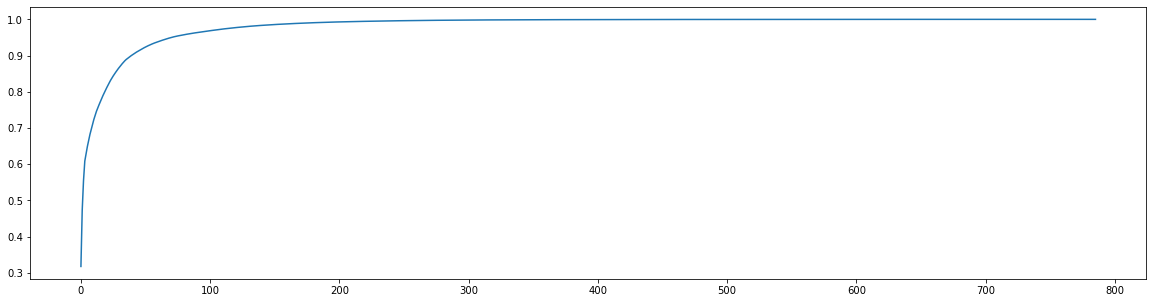

In [45]:
# this shows what proportion (y) of the total cells are assigned to the top x combinations
figsize(20,5)
plt.plot(simp_sums.values)

In [46]:
simps

0          (0, 1, 5)
1               (5,)
2             (0, 5)
3             (0, 5)
4          (0, 1, 5)
             ...    
7981312       (4, 5)
7981313       (0, 5)
7981314       (0, 5)
7981315       (1, 6)
7981316    (0, 1, 5)
Length: 7981317, dtype: object

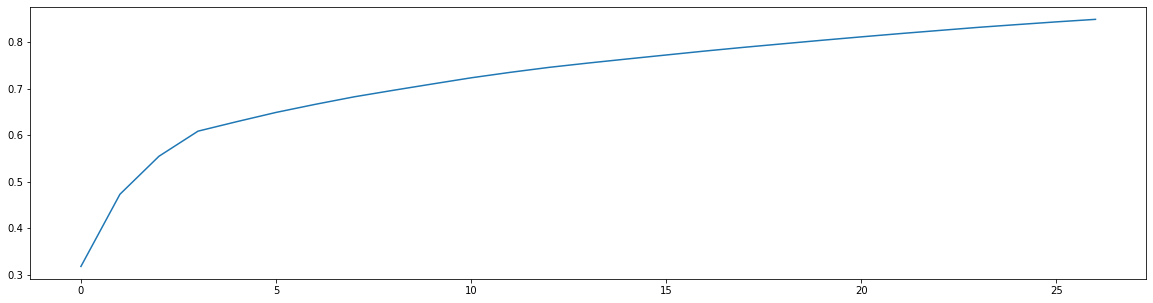

In [47]:
# this shows what proportion (y) of the total cells are assigned to the top x combinations
figsize(20,5)
plt.plot(test_sums_thres.values)
#plt.xticks(range(0,350,35),range(0,350,35),rotation = 90,fontsize = 10);

## Make network graph using the threshold above

In [48]:
g = nx.DiGraph()
thresh_cumulative = .95
thresh_freq = .001
#selected_simps = simp_sums[simp_sums<=thresh_cumulative].index.values
selected_simps = simp_freqs[simp_freqs>=thresh_freq].index.values

In [49]:
'''
this builds the graph for the CN combination map
'''
for e0 in selected_simps:
    for e1 in selected_simps:
        if (set(list(e0))<set(list(e1))) and (len(e1) == len(e0)+1):
            g.add_edge(e0,e1)

In [50]:
#Uses the top 20 combinations - for asterix
tops = simp_freqs[simp_freqs>=thresh_freq].sort_values(ascending = False).index.values.tolist()[:20]

### Assign colors to CNs

In [53]:
lmap = {j:i for i,j in enumerate(l)}
palt=pal_color
palt

{'Tumor boundary': '#5d5c61',
 'Myeloid-cell enriched immune infiltrate': 'sienna',
 'CAF-enriched stroma': 'orange',
 'B cell priming zone': '#3198b5',
 'T cell priming and activation': '#44CB63',
 'Bulk tumor': '#204F89',
 'Vessel-enriched stroma': 'red',
 'Plasma-cell enriched immune infiltrate': 'purple',
 'Epithelium': 'Magenta',
 'Follicle': '#0762eb',
 'Granulocyte-enriched': 'cyan'}

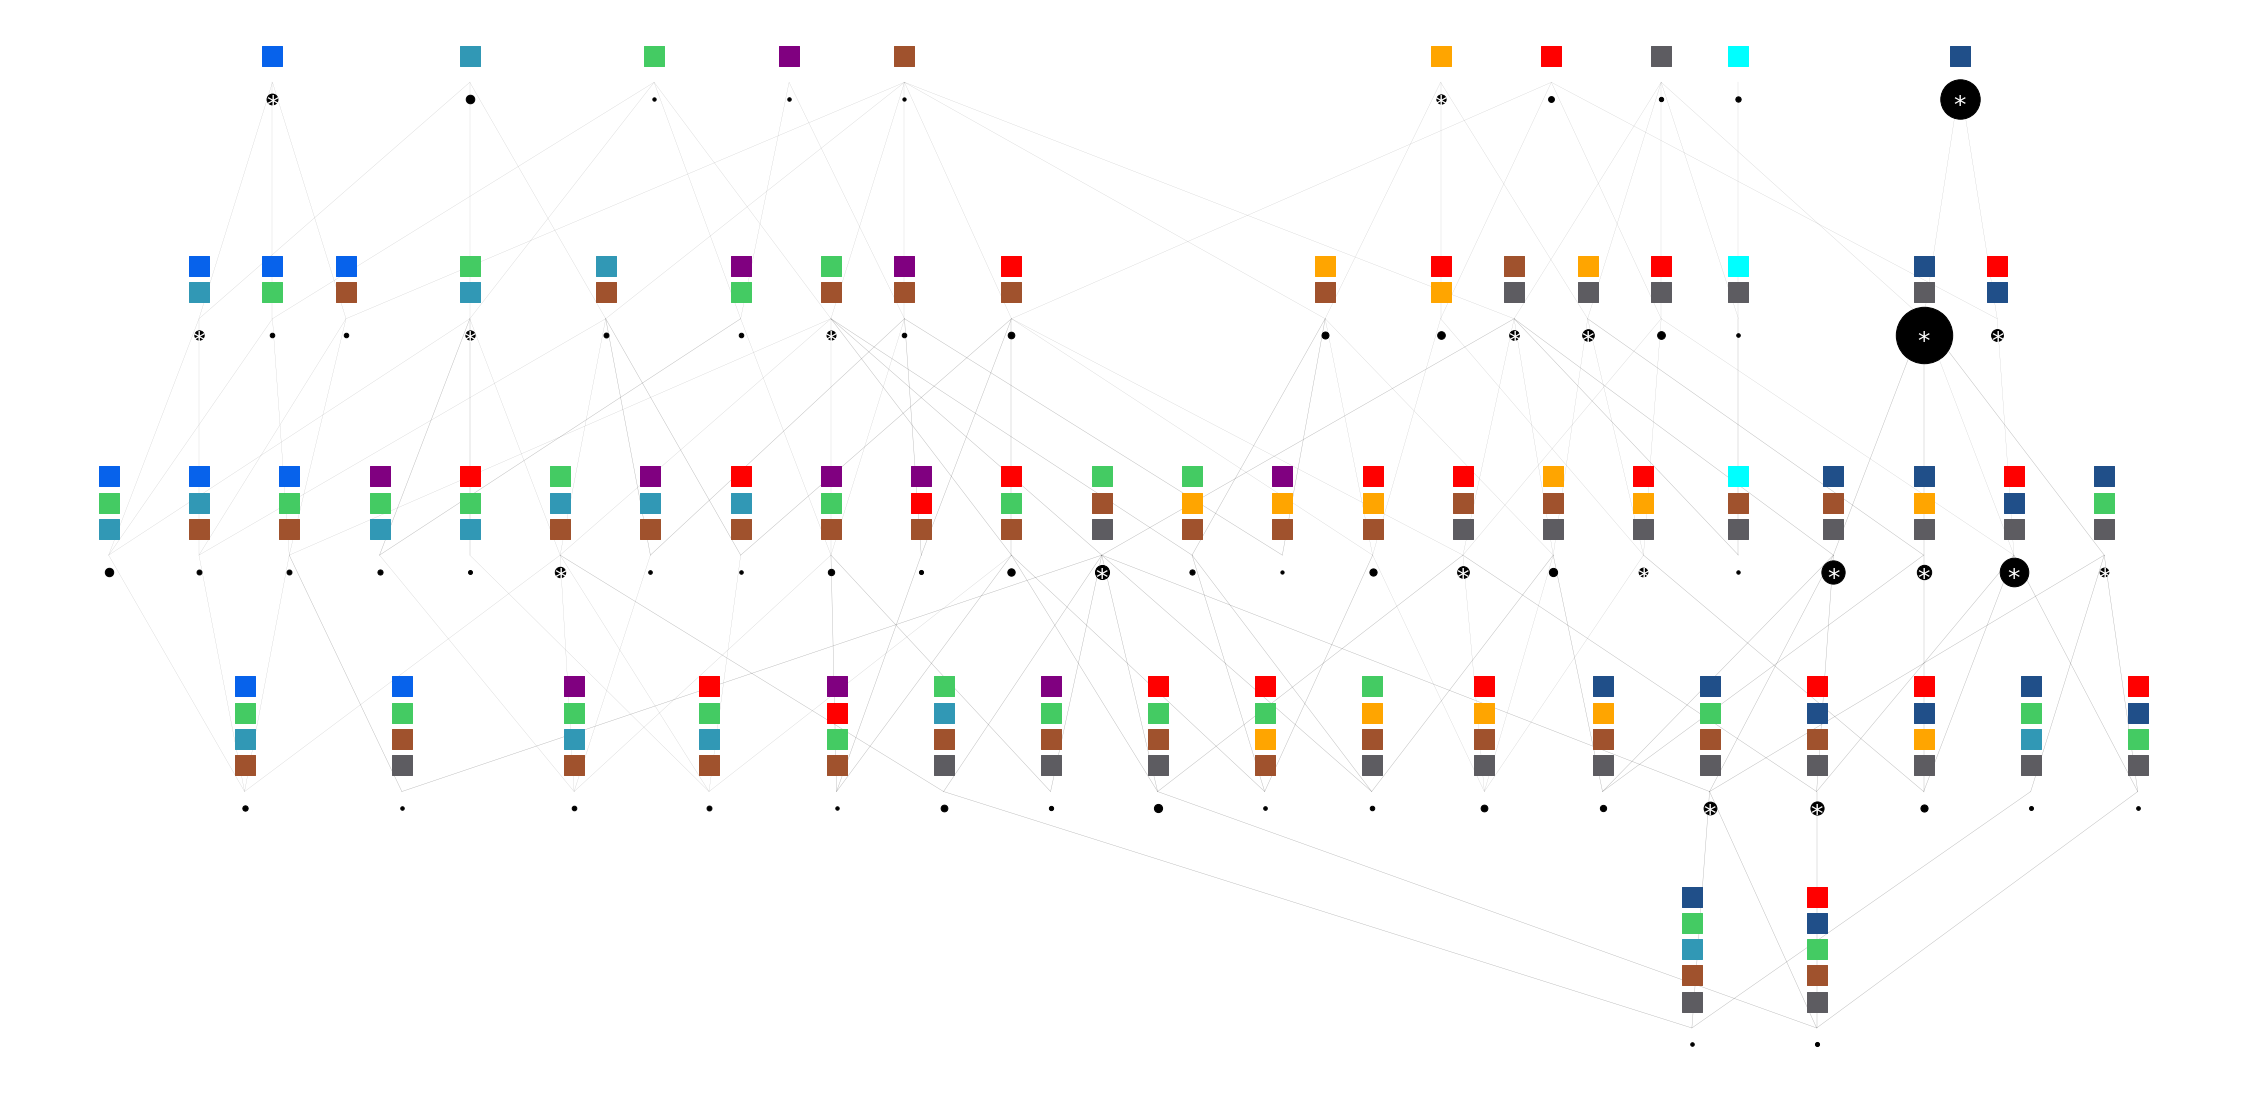

In [55]:
'''
this plots the CN combination map for the overall cohort
'''
draw = g
pos = nx.drawing.nx_pydot.graphviz_layout(draw, prog='dot')
height = 8

figsize(40,20)
for n in draw.nodes():
    col = 'black'
    if len(draw.in_edges(n))<len(n):
        col = 'black'
    plt.scatter(pos[n][0],pos[n][1]-5, s = simp_freqs[list(simp_freqs.index).index(n)]*10000, c = col, zorder = -1)
    if n in tops:
        plt.text(pos[n][0],pos[n][1]-7, '*', fontsize = 25, color = 'white', ha = 'center', va = 'center',zorder = 20)
    delta = 8
    #plot_sim((pos[n][0]+delta, pos[n][1]+delta),n, scale = 20,s = 200,text = True,fontsize = 15)
    plt.scatter([pos[n][0]]*len(n),[pos[n][1]+delta*(i+1) for i in range(len(n))],c = [palt[l[i]] for i in n] ,marker = 's', zorder = 5,s = 400)
    
#     #add profiles below node
#     x = pos[n][0]
#     y = pos[n][1]
#     y = y-height*2
#     standard_node_size =  16
#     node_heights = [0,3,8,5,3,2,1,5]
#     marker_colors = ['red','red','blue','blue','red','red','blue','blue']
    
#     plt.plot([x+(18*(i-1.5)) for i in range(len(node_heights))],[(y-height*.9)+v for v in node_heights],c = 'red',zorder =3)#,s = v*2 ,c= c,edgecolors='black',lw = 1)
#     plt.scatter([x+(18*(i-1.5)) for i in range(len(node_heights))],[(y-height*.9)+v for v in node_heights],c = marker_colors,s = standard_node_size,zorder = 4)
    
        
j = 0
for e0,e1 in draw.edges():
    weight = 0.2
    alpha = .3
    if len(draw.in_edges(e1))<len(e1):
        color = 'black'
        lw =1
        weight = 0.4
        
#     if (e0,e1) in set(draw.out_edges(tuple(sorted([lmap['3'],lmap['1']])))):
#         j+=1
#         print(j)
#         color = 'green'
#         weight = 2
#         alpha = 1
        
#     if (lmap['3'] in e0) and (lmap['1'] not in e0) and (lmap['1'] in e1):
#         color = 'green'
#         weight = 2
#         alpha = 1

    plt.plot([pos[e0][0], pos[e1][0]],[pos[e0][1], pos[e1][1]], color = col, linewidth = weight,alpha = alpha,zorder = -10)

plt.axis('off')
#plt.savefig('CNM.pdf')
plt.show()


-------------------

In [56]:
import os
os.getcwd()

'z:\\Max\\Computation\\Scripts\\5a Spatial contexts'

In [58]:
w.columns

Index(['UID', 'unique_core_num', 'cell_types_mediumres', 'cell_types_highres',
       'CN_k20_n25_annot', 'CPI_ORR', 'CPI_Progress_status',
       'Progress_to_metastatic_disease', 'Local_disease', 'Baseline_FU_biopsy',
       'x', 'y', 'PDL1_cluster_pos', 'PD1_cluster_pos', 'Tumor boundary',
       'Bulk tumor', 'Myeloid-cell enriched immune infiltrate',
       'Vessel-enriched stroma', 'T cell priming and activation',
       'CAF-enriched stroma', 'Follicle',
       'Plasma-cell enriched immune infiltrate', 'B cell priming zone',
       'Granulocyte-enriched', 'Epithelium', 'combination', 'combination_num'],
      dtype='object')

In [62]:
## Create data subset for patients that received ICB for advanced stage disease, include only baseline tissues taken before ICB start
w_new = w[w["Baseline_FU_biopsy"].isin(["pre", "FU"])]
w_sub_baseline = w_new[w_new["CPI_ORR"].isin(["0", "1"])]
w_sub_baseline

,UID,unique_core_num,cell_types_mediumres,cell_types_highres,CN_k20_n25_annot,CPI_ORR,CPI_Progress_status,Progress_to_metastatic_disease,Local_disease,Baseline_FU_biopsy,...,Vessel-enriched stroma,T cell priming and activation,CAF-enriched stroma,Follicle,Plasma-cell enriched immune infiltrate,B cell priming zone,Granulocyte-enriched,Epithelium,combination,combination_num
0,TMA_1_reg003_1,TMA_1_K7,tumor,tumor,Tumor boundary,1.0,0.0,1,0,pre,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Myeloid-cell enriched immune ...","(0, 1, 5)"
1,TMA_1_reg003_2,TMA_1_K7,tumor,tumor,Bulk tumor,1.0,0.0,1,0,pre,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Bulk tumor,)","(5,)"
2,TMA_1_reg003_3,TMA_1_K7,tumor,tumor,Bulk tumor,1.0,0.0,1,0,pre,...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Bulk tumor)","(0, 5)"
3,TMA_1_reg003_4,TMA_1_K7,tumor,tumor,Tumor boundary,1.0,0.0,1,0,pre,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Bulk tumor)","(0, 5)"
4,TMA_1_reg003_5,TMA_1_K7,tumor,tumor,Myeloid-cell enriched immune infiltrate,1.0,0.0,1,0,pre,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Myeloid-cell enriched immune ...","(0, 1, 5)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7959003,TMA_3_reg002_1385,TMA_3_L2,tumor,tumor,Myeloid-cell enriched immune infiltrate,0.0,1.0,1,0,pre,...,3.0,0.0,33.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, CAF-enriched stroma)","(0, 2)"
7959004,TMA_3_reg002_1386,TMA_3_L2,CAF,CD73_CAF,CAF-enriched stroma,0.0,1.0,1,0,pre,...,4.0,0.0,54.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, CAF-enriched stroma)","(0, 2)"
7959005,TMA_3_reg002_1387,TMA_3_L2,macrophages,M1_macrophages,Tumor boundary,0.0,1.0,1,0,pre,...,32.0,0.0,14.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, CAF-enriched stroma, Bulk tum...","(0, 2, 5, 6)"
7959006,TMA_3_reg002_1388,TMA_3_L2,stroma,stroma,Vessel-enriched stroma,0.0,1.0,1,0,pre,...,21.0,0.0,45.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Myeloid-cell enriched immune ...","(0, 1, 2, 6)"


In [68]:
## Create data subset for patients with initial local disease and only their tissue taken before progression to distant metastasis
w_local_disease_baseline = w[w["Baseline_FU_biopsy"].isin(["pre"])]
w_local_disease_baseline = w_local_disease_baseline[w_local_disease_baseline["Local_disease"].isin(["1"])]
w_local_disease_baseline

,UID,unique_core_num,cell_types_mediumres,cell_types_highres,CN_k20_n25_annot,CPI_ORR,CPI_Progress_status,Progress_to_metastatic_disease,Local_disease,Baseline_FU_biopsy,...,Vessel-enriched stroma,T cell priming and activation,CAF-enriched stroma,Follicle,Plasma-cell enriched immune infiltrate,B cell priming zone,Granulocyte-enriched,Epithelium,combination,combination_num
121183,TMA_1_reg008_122872,TMA_1_C7,tumor,tumor,Tumor boundary,0.0,1.0,1,1,pre,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Bulk tumor)","(0, 5)"
121184,TMA_1_reg008_122873,TMA_1_C7,tumor,tumor,Bulk tumor,0.0,1.0,1,1,pre,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Bulk tumor)","(0, 5)"
121185,TMA_1_reg008_122874,TMA_1_C7,tumor,tumor,Bulk tumor,0.0,1.0,1,1,pre,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Bulk tumor)","(0, 5)"
121186,TMA_1_reg008_122875,TMA_1_C7,macrophages,M2_macrophages,T cell priming and activation,0.0,1.0,1,1,pre,...,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Myeloid-cell enriched immune ...","(0, 1, 5)"
121187,TMA_1_reg008_122876,TMA_1_C7,tumor,tumor,Bulk tumor,0.0,1.0,1,1,pre,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Tumor boundary, Bulk tumor)","(0, 5)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7909973,TMA_44_reg095_276643,TMA_44_F1,VSMC,VSMC,Vessel-enriched stroma,1.0,1.0,1,1,pre,...,70.0,0.0,29.0,0.0,0.0,1.0,0.0,0.0,"(CAF-enriched stroma, Vessel-enriched stroma)","(2, 6)"
7909974,TMA_44_reg095_276644,TMA_44_F1,CD4T,CD4T,Myeloid-cell enriched immune infiltrate,1.0,1.0,1,1,pre,...,13.0,11.0,2.0,0.0,0.0,3.0,0.0,29.0,"(Tumor boundary, Myeloid-cell enriched immune ...","(0, 1, 4, 6, 8)"
7909975,TMA_44_reg095_276645,TMA_44_F1,CAF,CD73_CAF,T cell priming and activation,1.0,1.0,1,1,pre,...,7.0,5.0,0.0,1.0,0.0,11.0,0.0,0.0,"(Tumor boundary, Myeloid-cell enriched immune ...","(0, 1, 3, 5)"
7909976,TMA_44_reg095_276646,TMA_44_F1,CAF,CD73_CAF,Myeloid-cell enriched immune infiltrate,1.0,1.0,1,1,pre,...,0.0,21.0,0.0,0.0,0.0,31.0,0.0,0.0,"(Tumor boundary, Myeloid-cell enriched immune ...","(0, 1, 3, 4)"


#### Define network to plot CPI response vs CPI no response differences in terms of tissue architecture

In [65]:
def get_network(subset_list, ttl_per_thres, comb_per_thres,fig_size=(40,20), save_name=None):
    
    #Choose the windows size to continue with
    w_sub_baseline = windows[n_num]
    w_sub_baseline = w_sub_baseline[w_sub_baseline.CPI_ORR.isin(subset_list)]
    xm = w_sub_baseline.loc[:,l].values/n_num
          
    # Get the neighborhood combinations based on the threshold
    simps = get_thresh_simps(xm,ttl_per_thres)
    simp_freqs = simps.value_counts(normalize = True)
    simp_sums = np.cumsum(simp_freqs)
          
    g = nx.DiGraph()
    thresh_cumulative = .95
    thresh_freq = comb_per_thres
    #selected_simps = simp_sums[simp_sums<=thresh_cumulative].index.values
    selected_simps = simp_freqs[simp_freqs>=thresh_freq].index.values
          
    #this builds the graph for the CN combination map
    selected_simps
    for e0 in selected_simps:
        for e1 in selected_simps:
            if (set(list(e0))<set(list(e1))) and (len(e1) == len(e0)+1):
                g.add_edge(e0,e1)   

    #this plots the CN combination map

    draw = g
    pos = nx.drawing.nx_pydot.graphviz_layout(draw, prog='dot')
    height = 8

    figsize(*fig_size)
    for n in draw.nodes():
        col = 'black'
        if len(draw.in_edges(n))<len(n):
            col = 'black'
        plt.scatter(pos[n][0],pos[n][1]-5, s = simp_freqs[list(simp_freqs.index).index(n)]*10000, c = col, zorder = -1)
#         if n in tops:
#             plt.text(pos[n][0],pos[n][1]-7, '*', fontsize = 25, color = 'white', ha = 'center', va = 'center',zorder = 20)
        delta = 8
        #plot_sim((pos[n][0]+delta, pos[n][1]+delta),n, scale = 20,s = 200,text = True,fontsize = 15)
        plt.scatter([pos[n][0]]*len(n),[pos[n][1]+delta*(i+1) for i in range(len(n))],c = [palt[l[i]] for i in n] ,marker = 's', zorder = 5,s = 400)

    j = 0
    for e0,e1 in draw.edges():
        weight = 0.2
        alpha = .3
        if len(draw.in_edges(e1))<len(e1):
            color = 'black'
            lw =1
            weight = 0.4
        color='black'
        plt.plot([pos[e0][0], pos[e1][0]],[pos[e0][1], pos[e1][1]], color = color, linewidth = weight,alpha = alpha,zorder = -10)

    plt.axis('off')
    if save_name is not None:
        plt.savefig(save_path+save_name+'.pdf')#'.png', dpi=300)
    plt.show()



In [ ]:
w_sub_baseline["Progress_to_metastatic_disease"].value_counts()

In [ ]:
save_path = "Z:/Max/MCC_project/CODEX_final_Data/Output/Spatial_context_maps/CN_Combination_map/"
save_path

# Plot spatial context maps for CPI_response and CPI_non_response

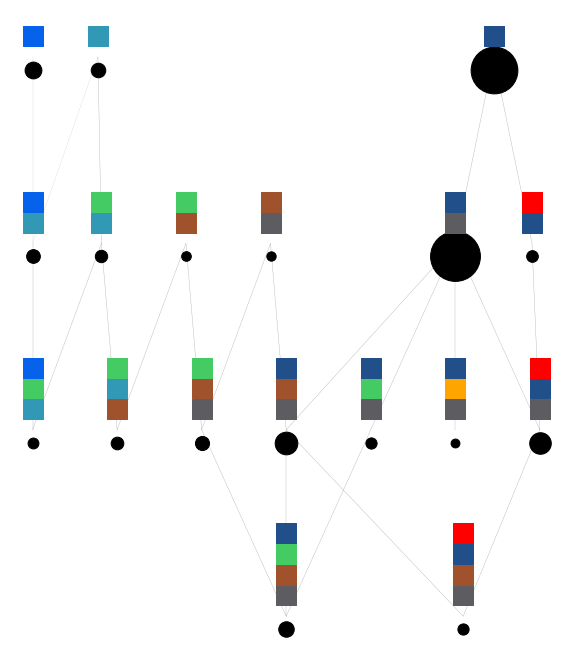

In [66]:
get_network(subset_list=['1'],ttl_per_thres=0.85, comb_per_thres=0.007,fig_size=(10,12),save_name=None)

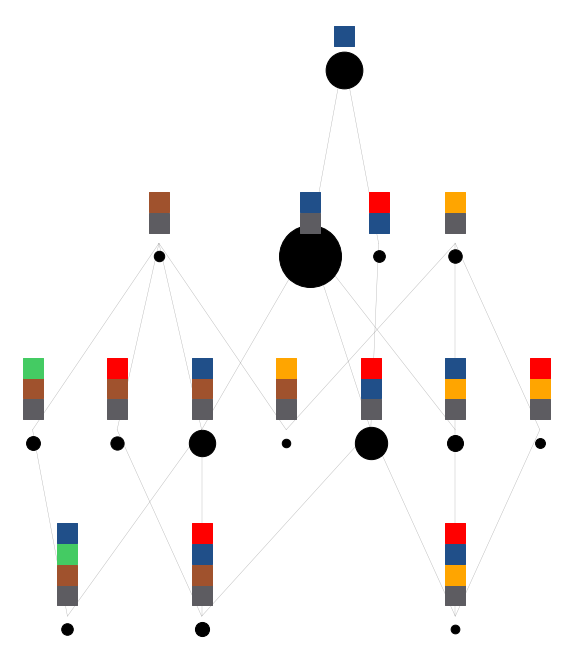

In [67]:
get_network(subset_list=['0'],ttl_per_thres=0.85, comb_per_thres=0.007,fig_size=(10,12),save_name=None)

# Plot Spatial context maps for patients with and without progression to distant metastasis that initially showed local_disease

In [69]:
def get_network(subset_list, ttl_per_thres, comb_per_thres,fig_size=(40,20), save_name=None):
    
    #Choose the windows size to continue with
    w_local_disease_baseline = windows[n_num]
    w_local_disease_baseline = w_local_disease_baseline[w_local_disease_baseline.Progress_to_metastatic_disease.isin(subset_list)]
    xm = w_local_disease_baseline.loc[:,l].values/n_num
          
    # Get the neighborhood combinations based on the threshold
    simps = get_thresh_simps(xm,ttl_per_thres)
    simp_freqs = simps.value_counts(normalize = True)
    simp_sums = np.cumsum(simp_freqs)
          
    g = nx.DiGraph()
    thresh_cumulative = .95
    thresh_freq = comb_per_thres
    #selected_simps = simp_sums[simp_sums<=thresh_cumulative].index.values
    selected_simps = simp_freqs[simp_freqs>=thresh_freq].index.values
          
    #this builds the graph for the CN combination map
    selected_simps
    for e0 in selected_simps:
        for e1 in selected_simps:
            if (set(list(e0))<set(list(e1))) and (len(e1) == len(e0)+1):
                g.add_edge(e0,e1)   

    #this plots the CN combination map

    draw = g
    pos = nx.drawing.nx_pydot.graphviz_layout(draw, prog='dot')
    height = 8

    figsize(*fig_size)
    for n in draw.nodes():
        col = 'black'
        if len(draw.in_edges(n))<len(n):
            col = 'black'
        plt.scatter(pos[n][0],pos[n][1]-5, s = simp_freqs[list(simp_freqs.index).index(n)]*10000, c = col, zorder = -1)
#         if n in tops:
#             plt.text(pos[n][0],pos[n][1]-7, '*', fontsize = 25, color = 'white', ha = 'center', va = 'center',zorder = 20)
        delta = 8
        #plot_sim((pos[n][0]+delta, pos[n][1]+delta),n, scale = 20,s = 200,text = True,fontsize = 15)
        plt.scatter([pos[n][0]]*len(n),[pos[n][1]+delta*(i+1) for i in range(len(n))],c = [palt[l[i]] for i in n] ,marker = 's', zorder = 5,s = 400)

    j = 0
    for e0,e1 in draw.edges():
        weight = 0.2
        alpha = .3
        if len(draw.in_edges(e1))<len(e1):
            color = 'black'
            lw =1
            weight = 0.4
        color='black'
        plt.plot([pos[e0][0], pos[e1][0]],[pos[e0][1], pos[e1][1]], color = color, linewidth = weight,alpha = alpha,zorder = -10)

    plt.axis('off')
    if save_name is not None:
        plt.savefig(save_path+save_name+'.pdf')#'.png', dpi=300)
    plt.show()



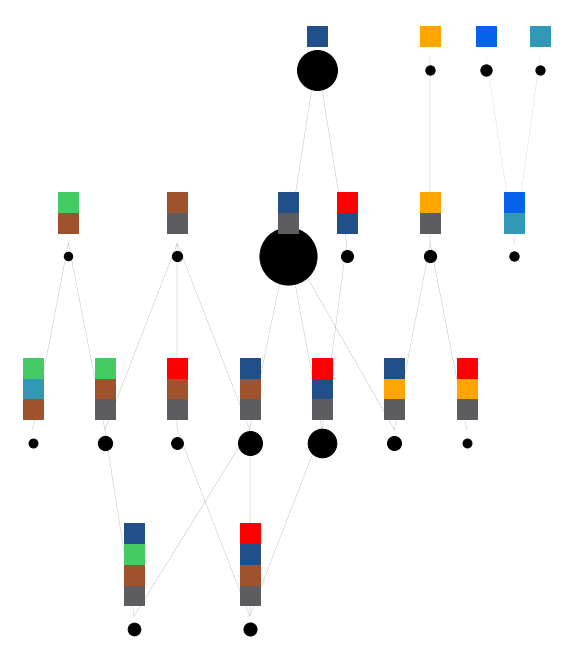

In [70]:
### Plotting spatial context maps for patients with distant metastasis upon initial local disease
get_network(subset_list=['1'],ttl_per_thres=0.85, comb_per_thres=0.007,fig_size=(10,12),save_name=None)

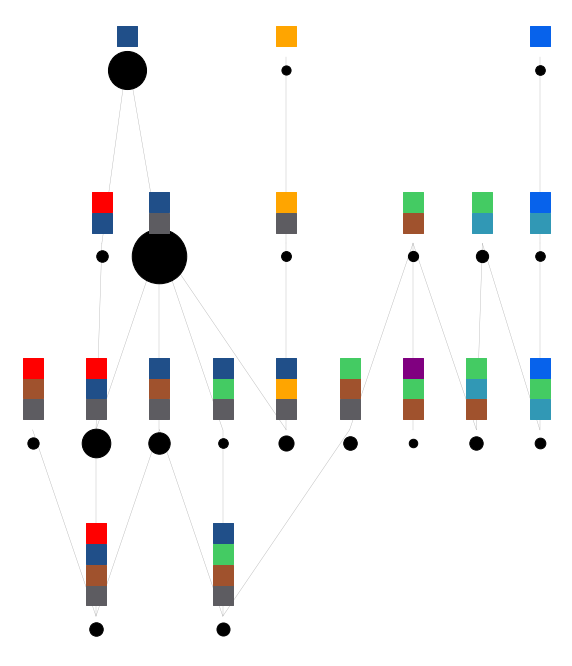

In [71]:
### Plotting spatial context maps for patients that did not develop distant metastasis upon local disease
get_network(subset_list=['0'],ttl_per_thres=0.85, comb_per_thres=0.007,fig_size=(10,12),save_name=None)